# 06 Vector PDF → LAS (no tracing)

Some well-log PDFs are not pictures: they were printed straight from logging software, so every curve is still stored as a line drawing (a *vector* path) with its exact coordinates, and the header and depth numbers are real text. For these files there is nothing to clean up or trace. pyLogDigitizer reads the paths, the depth numbers and the printed scales, converts each path to values, resamples them to the depth step you choose and writes LAS.

The example is a real public log: the merged petrophysical log of CCS1, the CO₂ injection well of the Illinois Basin – Decatur Project. It is compared at the end with the LAS file the log was plotted from.

## 1. The example and its source

- Well: CCS Well #1 (CCS1), ADM, Decatur, Macon County, Illinois (API 121152341500).
- Files: the Schlumberger merged petrophysical log, 2 in per 100 ft, one tall vector page (1.2 MB PDF), and the merged LAS it was plotted from (0–7350 ft, 0.5 ft, 12 curves; 2.2 MB).
- Source: Illinois State Geological Survey (ISGS), Illinois Basin – Decatur Project (IBDP), U.S. Department of Energy (DOE): *IBDP Well Information*, NETL Energy Data eXchange, https://doi.org/10.18141/1854144 (archive `ibdp_well_information.zip`, folder `IBDP_Geophysical_Logs/1211523415_CCS1/PEX_Petrophysical_Interpretations_V20150601`).
- License: IBDP dataset license (based on CC BY 4.0, non-commercial), https://co2datashare.org/view/license/e27b2b34-a3fc-463f-adbf-bd14c83640f4. This example data is for non-commercial use only. Credit: ISGS, IBDP, U.S. DOE.

The files are not stored in the repository. `fetch_ibdp_example` reads just these two files out of the 4.6 GB public archive (HTTP range requests, about 2 MB), checks their SHA-256 and keeps them in a local cache.

**Settings.** `STEP` is the depth step of the LAS file. The default is 0.5 ft; type any other step greater than 0. `ZOOM` is the depth window of the close-up figure.

In [1]:
# Settings: change these and re-run the notebook
STEP = 0.5               # LAS depth step in feet; any value greater than 0 works (the curves are exact paths)
ZOOM = (5400, 5700)      # depth window (ft) of the close-up figure

In [2]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

from pylogdigitizer import detect_input_kind
from pylogdigitizer.ibdp_examples import fetch_ibdp_example
from pylogdigitizer.pdf_vector import digitize_vector, read_vector_page, resample_path
from pylogdigitizer.pdf_vector.render import render_page
from pylogdigitizer.las_export import read_las

ROOT = Path(".").resolve()
if not (ROOT / "example_data").exists():
    ROOT = ROOT.parent
OUT = ROOT / "outputs" / "vector_ibdp_ccs1"
OUT.mkdir(parents=True, exist_ok=True)

folder = fetch_ibdp_example("CCS1")
PDF, LAS = folder / "CCS1_PEX_Merged_2in.pdf", folder / "CCS1_PEX_Merged.las"
print(PDF.name, PDF.stat().st_size, "bytes |", LAS.name, LAS.stat().st_size, "bytes")

CCS1_PEX_Merged_2in.pdf 1209760 bytes | CCS1_PEX_Merged.las 2188275 bytes


## 2. What kind of file is it?

The detector counts line paths, text characters and how much of the page is covered by pictures.

In [3]:
k = detect_input_kind(PDF, page=0)
print(f"{k.kind} -> {k.method_label}")
print("   ", k.evidence)
for n in k.notes:
    print("    note:", n)

vector -> vector workflow: read the curve paths exactly, no tracing
    {'n_paths': 72683, 'n_curve_paths': 4, 'text_chars': 2242, 'image_coverage': 0.0005, 'n_images': 1, 'page_size_pt': [594.0, 11772.0]}


## 3. Read the page

From the text and line drawing alone: the track borders, the depth numbers (fitted to a straight depth line), and each header entry with its name, left and right scale values, unit, and the colour and dash of its scale bar. Nothing here is typed in by hand. This print stacks up to five curves in one track, so the colour and dash of the scale bars are what tell the curves apart; the resistivity track is logarithmic.

In [4]:
vp = read_vector_page(PDF, page=0)
print("track borders (pt):", [round(b, 1) for b in vp.borders])
top_ft, bot_ft = (round(float(vp.depth(y)), 1) + 0.0 for y in (vp.plot_top, vp.plot_bottom))
print(f"depth labels: {len(vp.depth_labels)} | {top_ft:.1f} ft at the top to {bot_ft:.1f} ft at the bottom")
for h in vp.headers:
    style = "dashed" if h.dash else "solid"
    print(f"  {h.name:6s} {h.left:>6g} to {h.right:<6g} {h.unit:8s} {h.kind:6s} x {h.x0:5.1f}-{h.x1:5.1f} pt  bar {style}")

track borders (pt): [0.0, 18.0, 36.0, 53.9, 71.9, 89.9, 107.9, 125.8, 143.8, 161.8, 179.8, 233.7, 278.7, 323.6, 368.6, 413.5, 431.5, 449.5, 467.4, 485.4, 503.4, 521.4, 539.3, 557.3, 575.3, 593.3]
depth labels: 74 | 0.0 ft at the top to 7350.0 ft at the bottom
  RHOZ     1.95 to 2.95   g/cm3    linear x 413.5-593.3 pt  bar solid
  RLA5      0.2 to 2000   ohm.m    log    x 233.7-413.5 pt  bar solid
  HTNP     0.45 to -0.15  ft3/ft3  linear x 413.5-593.3 pt  bar dashed
  HSGR        0 to 150    GAPI     linear x   0.0-179.8 pt  bar solid
  RLA4      0.2 to 2000   ohm.m    log    x 233.7-413.5 pt  bar solid
  DTCO      140 to 40     US/FT    linear x 413.5-593.3 pt  bar solid
  HCAL        6 to 26     in       linear x   0.0-179.8 pt  bar dashed
  RLA3      0.2 to 2000   ohm.m    log    x 233.7-413.5 pt  bar solid
  DTSM      240 to 80     US/FT    linear x 413.5-593.3 pt  bar solid
  BS          6 to 26     in       linear x   0.0-179.8 pt  bar dashed
  RLA2      0.2 to 2000   ohm.m    lo

## 4. Curves to values, then LAS

Each curve path is matched to its header (same track, then same colour and dash) and every path point is turned into a value on that printed scale: these are the exact plotted numbers, not a trace. This file draws each curve as thousands of short two-point pieces; they are joined back into one path per curve first. The points are then resampled to the depth step `STEP` set above; breaks in a path stay empty. Paths with no printed scale would be skipped and listed in the notes.

In [5]:
assert STEP > 0, "STEP must be greater than 0"
log = digitize_vector(PDF, page=0, step=STEP)
print("reader:", log.info["reader"], "| step", log.step, "ft |", len(log.depth), "samples |", log.well)
for t in log.traces:
    print(f"  {t.mnemonic:6s} {t.unit:8s} {t.info['n_pts']:6d} path points, matched by {t.info['matched_by']}")
for n in log.info["notes"]:
    print("note:", n)
import warnings
with warnings.catch_warnings():
    warnings.simplefilter("ignore")      # PEFZ has no unit printed on the PDF
    las_out = log.to_las(OUT / "CCS1_vector.las")
print("wrote", Path(las_out).relative_to(ROOT))

reader: vector | step 0.5 ft | 14699 samples | {'WELL': 'CCS WELL #1', 'COMP': 'ADM COMPANY', 'FLD': 'Wildcat', 'CTRY': 'USA'}
  RHOZ   g/cm3      8712 path points, matched by colour
  RLA5   ohm.m      8390 path points, matched by colour
  HTNP   ft3/ft3    8456 path points, matched by colour
  HSGR   GAPI       9030 path points, matched by colour
  RLA4   ohm.m      8305 path points, matched by colour
  DTCO   US/FT      7334 path points, matched by colour
  HCAL   in         6104 path points, matched by colour
  RLA3   ohm.m      7560 path points, matched by colour
  DTSM   US/FT      7238 path points, matched by colour
  BS     in         4901 path points, matched by colour
  RLA2   ohm.m      6784 path points, matched by colour
  PEFZ              6834 path points, matched by colour


wrote outputs/vector_ibdp_ccs1/CCS1_vector.las


The resampling step is free: `resample_path` takes any positive step. For example, the gamma-ray path at 0.1 ft:

In [6]:
t = next(t for t in log.traces if t.mnemonic == "HSGR")
d01, v01 = resample_path(t.depth, t.value, 0.1)
print(t.mnemonic, len(d01), "samples at 0.1 ft from", np.isfinite(t.depth).sum(), "path points")

HSGR 70836 samples at 0.1 ft from 9030 path points


## 5. Compare with the LAS

The LAS holds the values the log was plotted from. The comparison uses only depths where the LAS value is inside the printed scale (outside it the PDF curve is clipped at the track edge). For the logarithmic resistivity curves `r` and the difference are taken on log10 of the values.

In [7]:
ref = read_las(LAS).df()
rows = []
for t in log.traces:
    s = ref[t.mnemonic].dropna()
    rv = np.interp(log.depth, s.index.values, s.values, left=np.nan, right=np.nan)
    v = log.curves[t.mnemonic]
    lo, hi = sorted((t.info["left"], t.info["right"]))
    ok = np.isfinite(v) & np.isfinite(rv) & (rv >= lo) & (rv <= hi)
    a, b = (np.log10(v[ok]), np.log10(rv[ok])) if t.kind == "log" else (v[ok], rv[ok])
    r = np.corrcoef(a, b)[0, 1]; d = np.abs(a - b)
    unit = "log10" if t.kind == "log" else t.unit
    rows.append((t.mnemonic, int(ok.sum()), r, np.median(d), np.percentile(d, 95)))
    print(f"{t.mnemonic:6s} n={ok.sum():6d}  r={r:.4f}  median |diff|={np.median(d):.2g}  95th pct |diff|={np.percentile(d, 95):.2g} {unit}")

RHOZ   n= 13696  r=0.9989  median |diff|=3.6e-07  95th pct |diff|=0.011 g/cm3
RLA5   n= 13756  r=0.9997  median |diff|=4e-07  95th pct |diff|=0.043 log10
HTNP   n= 12454  r=0.9994  median |diff|=1.1e-07  95th pct |diff|=0.0072 ft3/ft3
HSGR   n= 13467  r=0.9997  median |diff|=3.6e-06  95th pct |diff|=1.7 GAPI
RLA4   n= 13781  r=0.9997  median |diff|=4e-07  95th pct |diff|=0.042 log10
DTCO   n= 13739  r=0.9996  median |diff|=2.3e-05  95th pct |diff|=0.86 US/FT
HCAL   n= 14052  r=0.9993  median |diff|=0.0038  95th pct |diff|=0.12 in
RLA3   n= 13783  r=0.9997  median |diff|=4.8e-07  95th pct |diff|=0.038 log10
DTSM   n= 12513  r=0.9997  median |diff|=3.3e-05  95th pct |diff|=1.4 US/FT
BS     n= 14699  r=1.0000  median |diff|=4.6e-07  95th pct |diff|=4.6e-07 in
RLA2   n= 13781  r=0.9996  median |diff|=9.5e-05  95th pct |diff|=0.03 log10
PEFZ   n= 14437  r=0.9997  median |diff|=0.00094  95th pct |diff|=0.067 


Every curve matches the LAS to within the precision of the plot. The small differences (95th percentile) come from the plotting software thinning the 0.5 ft data at this 2 in per 100 ft print scale, not from the reading.

## 6. Figures

All curves over the full depth (digitized in colour, LAS in grey), then a close-up of `ZOOM` beside the page as drawn.

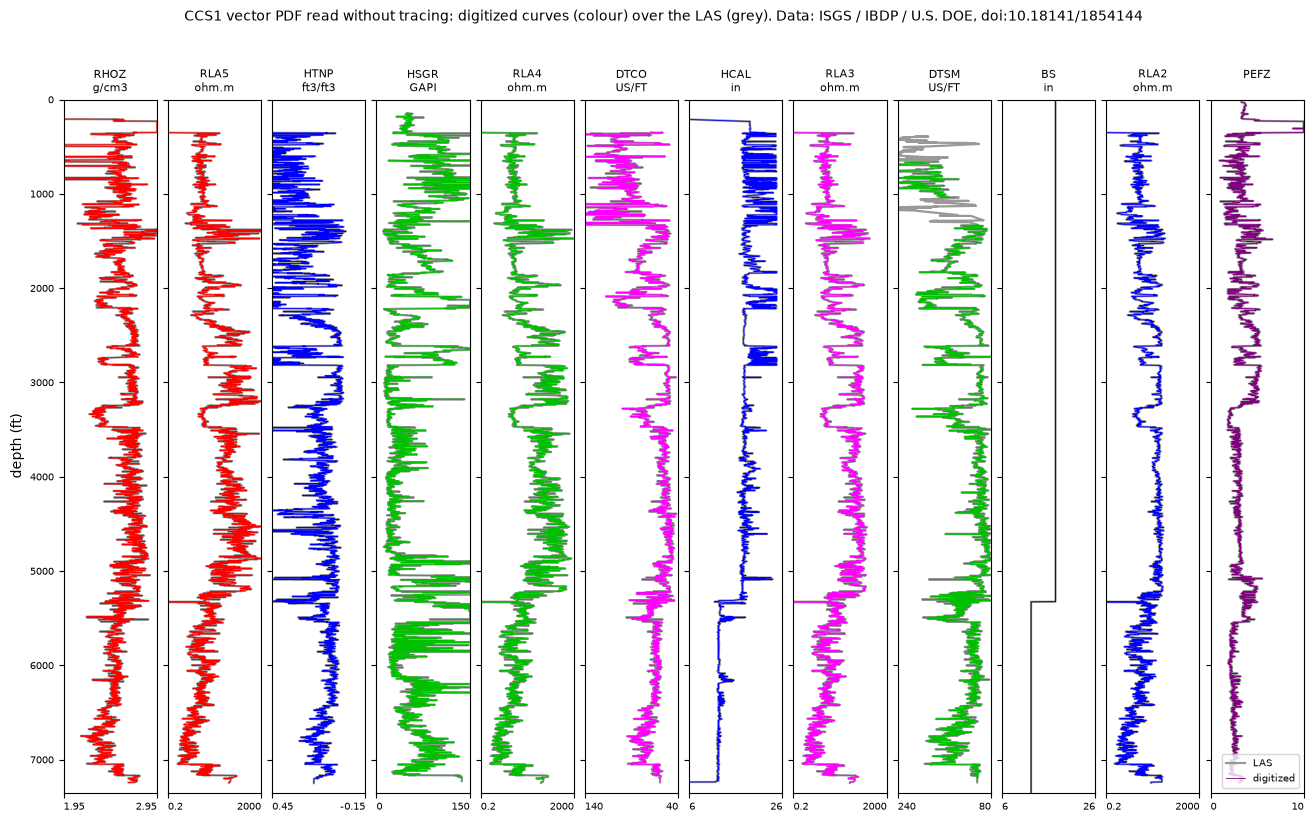

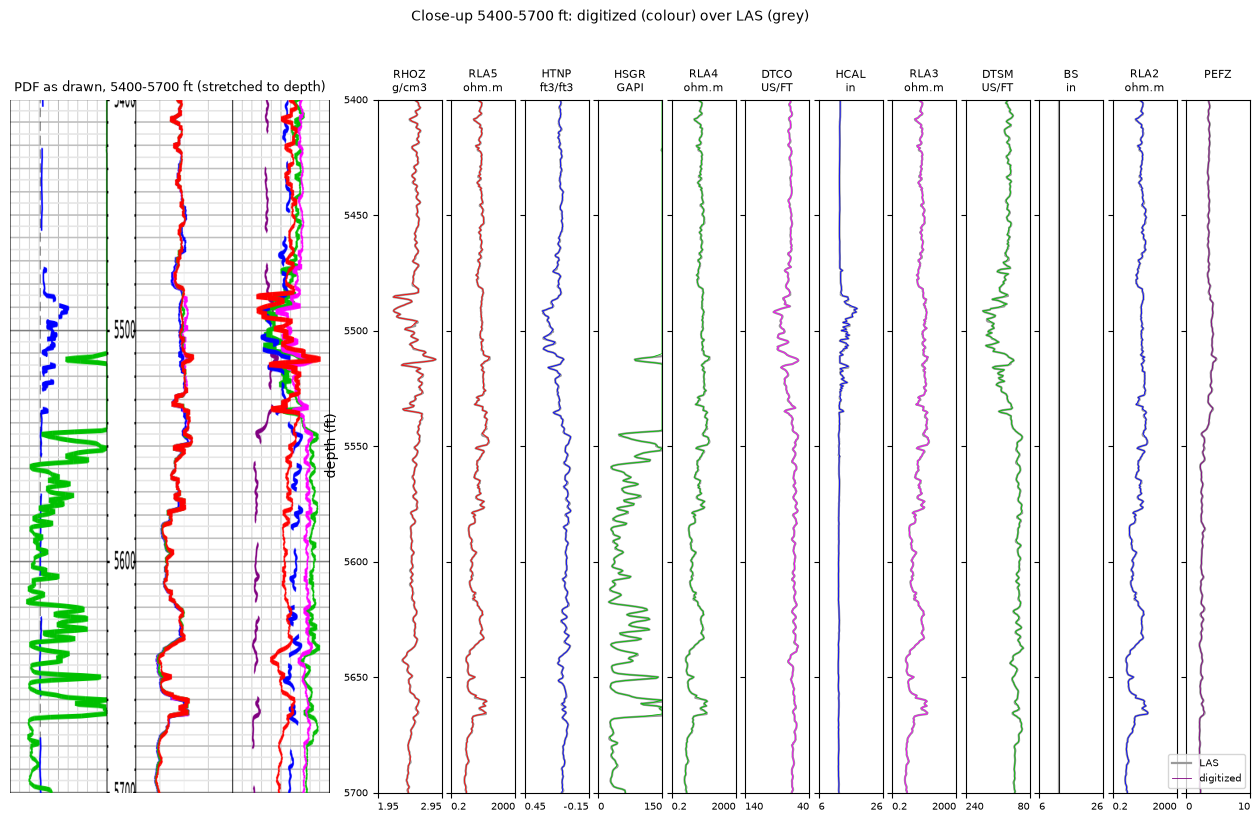

saved outputs/vector_ibdp_ccs1/CCS1_vector_vs_las.png and outputs/vector_ibdp_ccs1/CCS1_vector_vs_las_zoom.png


In [8]:
def panels(fig, gs, d0, d1, first):
    for i, t in enumerate(log.traces):
        ax = fig.add_subplot(gs[i + first])
        s = ref[t.mnemonic].dropna(); s = s[(s.index >= d0) & (s.index <= d1)]
        ax.plot(s.values, s.index.values, color="0.6", lw=1.6, label="LAS")
        m = (log.depth >= d0) & (log.depth <= d1)
        ax.plot(log.curves[t.mnemonic][m], log.depth[m], color=t.color or "C0", lw=0.6, label="digitized")
        lo, hi = t.info["left"], t.info["right"]
        if t.kind == "log":
            ax.set_xscale("log")
        ax.set_xlim(lo, hi); ax.set_ylim(d1, d0)
        ax.set_xticks([lo, hi]); ax.set_xticklabels([f"{lo:g}", f"{hi:g}"]); ax.minorticks_off()
        for lab, ha in zip(ax.get_xticklabels(), ("left", "right")):
            lab.set_ha(ha)
        ax.set_title(f"{t.mnemonic}\n{t.unit}", fontsize=8); ax.tick_params(labelsize=7)
        if i:
            ax.set_yticklabels([])
        else:
            ax.set_ylabel("depth (ft)")
    ax.legend(fontsize=7, loc="lower right")

n = len(log.traces)
fig = plt.figure(figsize=(16, 9))
gs = fig.add_gridspec(1, n, wspace=0.12)
panels(fig, gs, np.nanmin(log.depth), np.nanmax(log.depth), 0)
fig.suptitle("CCS1 vector PDF read without tracing: digitized curves (colour) over the LAS (grey). "
             "Data: ISGS / IBDP / U.S. DOE, doi:10.18141/1854144", fontsize=10)
fig.savefig(OUT / "CCS1_vector_vs_las.png", dpi=110, bbox_inches="tight"); plt.show()

# close-up beside the page as drawn
scale = 2.0
img = render_page(PDF, 0, scale=scale)
a, b = vp.depth_fit                               # depth = a + b * y (y in PDF points, up)
rows_px = sorted(int(round((vp.height - (d - a) / b) * scale)) for d in ZOOM)
fig = plt.figure(figsize=(16, 9))
gs = fig.add_gridspec(1, 2 + n, width_ratios=[5, 0.45] + [1] * n, wspace=0.12)   # a spacer for the depth axis
ax0 = fig.add_subplot(gs[0]); ax0.imshow(img[rows_px[0]:rows_px[1]], aspect="auto"); ax0.axis("off")
ax0.set_title(f"PDF as drawn, {ZOOM[0]}-{ZOOM[1]} ft (stretched to depth)", fontsize=9)
panels(fig, gs, *ZOOM, 2)
fig.suptitle(f"Close-up {ZOOM[0]}-{ZOOM[1]} ft: digitized (colour) over LAS (grey)", fontsize=10)
fig.savefig(OUT / "CCS1_vector_vs_las_zoom.png", dpi=110, bbox_inches="tight"); plt.show()
print("saved", (OUT / "CCS1_vector_vs_las.png").relative_to(ROOT), "and", (OUT / "CCS1_vector_vs_las_zoom.png").relative_to(ROOT))

## Notes

- A vector PDF can also be opened in the interactive app: the Open scan tab shows the detected input type, skips the tracing steps and goes straight to Check and save.
- Pages turned sideways (landscape logs) are read the same way, in the frame where the log stands upright.
- For a *mixed* PDF (a scanned picture with real text on top) the header and scales come from the PDF text and the curves are traced from the picture.